# Assignment 4

## Q1. The Blasius equation appears in fluid mechanics as a laminar flow boundary layer and is written:

$$y^{\prime\prime\prime} + y y^{\prime\prime} = 0 $$

### a) Express this 3rd order ODE as a system of first order ODEs.

Turn it into first-order ODEs. Make one variable for each derivative.

y1 = y
y2 = y'
y3 = y"

y1' = y2

y2' = y3

y3' = −y1·y3

### b) Solve for $y(z)$ as an initial value problem assuming the boundary conditions below and plot the answer:

$$
\begin{align}
y(z=0) &= 0 \\
y^\prime(z=0) &= 0 \\
y^{\prime\prime}(z = 0) &= 1 \\
\end{align}
$$

HINT: Read and consider part c) before implementing this.


**Method** : Initial value problem with RK45 (solve_ivp)
All three conditions are z = 0, so the system from a) is soolved forward from [y1,y2,y3] = [0,0,1]. It's written as a function of s = y"(0) so part c) can reuse it.

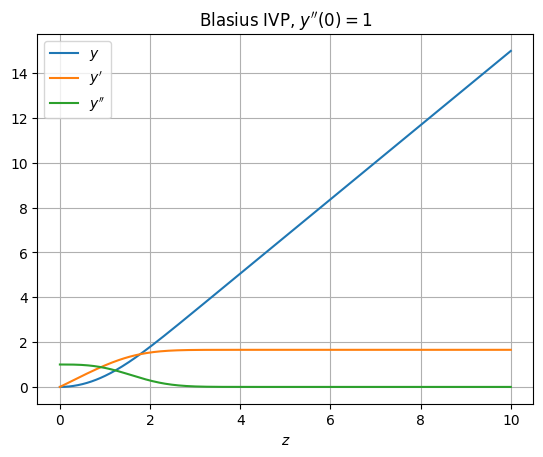

y'(z=L) = 1.6551903703059747


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root

L = 10 #large z used in place of infinity

def model(z,y):
  return [y[1], y[2], -y[0]*y[2]]

def solve(s, L=L):
  return solve_ivp(model, [0, L], [0, 0, s], method='RK45', dense_output=True, rtol=1e-8, atol=1e-8)

sol_b = solve(1.0)
z = np.linspace(0, L, 400)
y, yp, ypp = sol_b.sol(z)

plt.plot(z, y, label="$y$")
plt.plot(z, yp, label="$y'$")
plt.plot(z, ypp, label="$y''$")
plt.xlabel("$z$"); plt.title("Blasius IVP, $y''(0) = 1$")
plt.legend(); plt.grid(); plt.show()

print("y'(z=L) =", sol_b.y[1][-1])



With y"(0) = 1, y' rises and levels off at y'(10) = ~1.655, while y" decays to 0 and y grows linearly once y' is constant. Since y' only reaches about 1.655, this initial value doesn't satisfy y'(∞) = 2

## c) Use your *method* from b) to find a value of $y''(z=0)$ such that $y(z)$ fits the boundary conditions below, and plot the answer:

$$
\begin{align}
y(z=0) &= 0 \\
y^\prime(z=0) &= 0 \\
y^{\prime}(z = \infty) &= 2 \\
\end{align}
$$

Method: Shooting method

y"(0) isn't given. Instead, y' has to equal 2 at z = ∞. So guess s = y"(0), solve with the method from b), and check the miss F(s) = y'(10)-2. A root finder adjusts s until the miss is zero.

z = 10 is used in place of ∞ because y' has already leveled off by then.



y''(0) = 1.3282293339038347
L = 8: y''(0) = 1.3282293337110693
L = 10: y''(0) = 1.3282293339038347
L = 15: y''(0) = 1.32822933351032


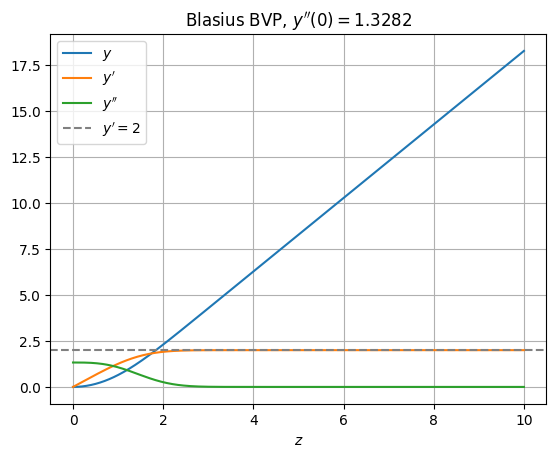

In [3]:
def shooting_method(s, L=L):
  sol = solve(s[0], L)
  return sol.y[1][-1] - 2

result = root(shooting_method, 1)
s_star = result.x[0]
print("y''(0) =", s_star)

for Lc in [8, 10, 15]:
    print(f"L = {Lc}: y''(0) =", root(lambda s: shooting_method(s, Lc), 1).x[0])

sol_c = solve(s_star)
y, yp, ypp = sol_c.sol(z)
plt.plot(z, y, label="$y$")
plt.plot(z, yp, label="$y'$")
plt.plot(z, ypp, label="$y''$")
plt.axhline(2, ls="--", c="gray", label="$y' = 2$")
plt.xlabel("$z$"); plt.title(f"Blasius BVP, $y''(0) = {s_star:.4f}$")
plt.legend(); plt.grid(); plt.show()


Therefore y″(0) ≈ 1.328. The result is the same for L = 8, 10 and 15, so L = 10 is a good stand-in for infinity. The plot shows y′ leveling off at 2, so all three boundary conditions are met.

## Q2

The Fourier series shows that periodic functions can be written as an infinite sum of sine and cosine waves:

 $$f(x)= \frac{A_0}{2}+\sum_{n=1}^{\infty}A_n\ \cos{(nx)} + B_n\ \sin{(nx)}$$

Due to function orthogonality, the values of $A_n$ and $B_n$ can be computed using the following formulae:

 $$A_n= \frac{1}{\pi} \int_{-\pi}^{\pi} f(x) \cos{(nx)}\ dx$$
 $$B_n= \frac{1}{\pi} \int_{-\pi}^{\pi} f(x) \sin{(nx)}\ dx$$

Periodic functions can be approximated by truncating the Fourier series at some $n = N$.

### 2a

Write a function that takes a $2-\pi$ periodic function and a degree $n$, then outputs the $n-th$ Fourier coefficients $[A_n, B_n]$. Use the equations above with a suitable integration method. (Don't use packaged Fourier analysis tools)

Test it for a suitable set of functions for which you have an analytic answer.

E.g.: f(x) = sin(3x) + 2cos(x) would have:

| **n** | **A** | **B** |
|---|---|---|
| **0** | 0 | 0 |
| **1** | 2 | 0 |
| **2** | 0 | 0 |
| **3** | 0 | 1 |

{implementation, answer}

In [5]:
import numpy as np

def trap(y, x):
  h = x[1] - x[0]
  return h * (y[0]/2 + y[1:-1].sum() + y[-1]/2)

def fourier(f, n, M=20001):
    x = np.linspace(-np.pi, np.pi, M)
    fx = np.asarray(f(x), dtype=float)
    A = np.array([trap(fx*np.cos(k*x), x)/np.pi for k in range(n+1)])
    B = np.array([trap(fx*np.sin(k*x), x)/np.pi for k in range(n+1)])
    return A, B

def show(f, n):
    A, B = fourier(f, n)
    print(" n       A        B")
    for k in range(n+1):
        print(f"{k:2d}  {A[k]:8.4f} {B[k]:8.4f}")

show(lambda x: np.sin(3*x) + 2*np.cos(x), 3)
show(lambda x: np.cos(4*x) - 5*np.sin(2*x), 4)


 n       A        B
 0    0.0000   0.0000
 1    2.0000   0.0000
 2    0.0000   0.0000
 3   -0.0000   1.0000
 n       A        B
 0    0.0000   0.0000
 1   -0.0000  -0.0000
 2   -0.0000  -5.0000
 3    0.0000  -0.0000
 4    1.0000  -0.0000


For f(x) = sin(3x) + 2cos(x), the function returns A1 = 2 and B3 = 1, with all other coefficients = ~ 0.  This matches the analytic answer from the question, so the function correctly is computed.

### 2b
Find the coefficients of the following functions and expansion orders:
{All answers}

In [6]:
f = lambda x: np.mod(x, np.pi/2)
N = 5
show(f,N)

 n       A        B
 0    1.5705   0.0000
 1    0.0000   0.0000
 2   -0.0000   0.0000
 3    0.0000   0.0000
 4   -0.0003  -0.5000
 5    0.0000  -0.0000


A₀ ≈ 1.5708, B₄ ≈ −0.5, all other coefficients ≈ 0.

In [7]:
f = lambda x: np.mod(x, np.pi/2)
N = 20
show(f, N)

 n       A        B
 0    1.5705   0.0000
 1    0.0000   0.0000
 2   -0.0000   0.0000
 3    0.0000   0.0000
 4   -0.0003  -0.5000
 5    0.0000  -0.0000
 6   -0.0000   0.0000
 7    0.0000   0.0000
 8   -0.0003  -0.2500
 9    0.0000  -0.0000
10   -0.0000   0.0000
11    0.0000   0.0000
12   -0.0003  -0.1667
13    0.0000  -0.0000
14   -0.0000  -0.0000
15    0.0000   0.0000
16   -0.0003  -0.1250
17    0.0000  -0.0000
18   -0.0000   0.0000
19    0.0000   0.0000
20   -0.0003  -0.1000


A₀ ≈ 1.5708, B₄ = −0.5, B₈ = −0.25, B₁₂ = −0.1667, B₁₆ = −0.125, B₂₀ = −0.1, all other coefficients ≈ 0.

In [8]:
f = lambda x: (x > -np.pi/2) & (x < np.pi/2)
N = 2
show(f, N)

 n       A        B
 0    0.9999   0.0000
 1    0.6366   0.0000
 2    0.0001   0.0000


A₀ ≈ 1, A₁ ≈ 0.6366, all other coefficients ≈ 0.

In [9]:
f = lambda x: (x > -np.pi/2) & (x < np.pi/2)
N = 20
show(f,N)

 n       A        B
 0    0.9999   0.0000
 1    0.6366   0.0000
 2    0.0001   0.0000
 3   -0.2122   0.0000
 4   -0.0001   0.0000
 5    0.1273  -0.0000
 6    0.0001   0.0000
 7   -0.0909   0.0000
 8   -0.0001  -0.0000
 9    0.0707  -0.0000
10    0.0001   0.0000
11   -0.0579   0.0000
12   -0.0001   0.0000
13    0.0490  -0.0000
14    0.0001  -0.0000
15   -0.0424   0.0000
16   -0.0001   0.0000
17    0.0374  -0.0000
18    0.0001   0.0000
19   -0.0335   0.0000
20   -0.0001  -0.0000


A₀ ≈ 1, A₁ = 0.6366, A₃ = −0.2122, A₅ = 0.1273, A₇ = −0.0909, A₉ = 0.0707, A₁₁ = −0.0579, A₁₃ = 0.0490, A₁₅ = −0.0424, A₁₇ = 0.0374, A₁₉ = −0.0335, all other coefficients ≈ 0.

## Q3:

Given $$\int_{-1}^1 f(x) dx = 3$$ and $$f(-3^{-\frac{1}{2}}) = 1$$

Assuming $f$ is a cubic polynomial, what is $f(3^{-\frac{1}{2}})$? Why?

Use the 2-point Guass-Legendre quadrature approximates.

$$\int_{-1}^{1} f(x)\,dx \approx f\left(-\tfrac{1}{\sqrt{3}}\right) + f\left(\tfrac{1}{\sqrt{3}}\right)$$


3 = $$3 = f\left(-\tfrac{1}{\sqrt{3}}\right) + f\left(\tfrac{1}{\sqrt{3}}\right) = 1 + f\left(\tfrac{1}{\sqrt{3}}\right)$$


So f(1/√3) = 3 − 1 = 2.

